# Notebook for exploration of the RDD2022

## Assumptions Made in This Notebook

This notebook is used to explore and understand the RDD2022 dataset before starting model training. The main goal is to check how the dataset is structured, how the labels are stored, what classes are present, and whether there are any important issues that need to be considered before training an object detection model.

At this stage, the notebook does **not** train a model and does **not** modify the dataset. It is only used for exploratory data analysis.

---

### 1. Dataset Location Assumption

The notebook assumes that the RDD2022 dataset is stored inside the project folder under:

```text
data/raw/RDD2022/
```

The expected structure is:

```text
data/raw/RDD2022/
├── train/
│   ├── images/
│   └── labels/
├── val/
│   ├── images/
│   └── labels/
└── test/
    ├── images/
    └── labels/
```

Because this notebook is located inside the `notebooks/` folder, the dataset path is defined as:

```python
DATASET_ROOT = Path("../data/raw/RDD2022")
```

This means the notebook looks one folder level above the notebook folder to find the dataset.

---

### 2. Dataset Split Assumption

The notebook assumes that the dataset has already been divided into three splits:

- training set
- validation set
- test set

These splits are used exactly as they were provided in the downloaded dataset. No new split is created in this notebook.

The dataset contains:

| Split | Images | Labels |
|---|---:|---:|
| train | 26,869 | 26,869 |
| val | 5,758 | 5,758 |
| test | 5,758 | 5,758 |

This shows that every split contains the same number of image files and label files.

---

### 3. Image and Label Matching Assumption

The notebook assumes that every image has a corresponding label file with the same filename.

For example:

```text
images/China_Drone_000048.jpg
labels/China_Drone_000048.txt
```

This is important because YOLO expects each image to have a matching `.txt` label file. The label file can either contain one or more objects, or it can be empty if there are no annotated objects in the image.

---

### 4. Label Format Assumption

The notebook assumes that the labels are already stored in YOLO format.

Each row in a label file is expected to follow this structure:

```text
class_id x_center y_center bbox_width bbox_height
```

Where:

- `class_id` is the numeric ID of the damage class.
- `x_center` is the normalized horizontal center of the bounding box.
- `y_center` is the normalized vertical center of the bounding box.
- `bbox_width` is the normalized width of the bounding box.
- `bbox_height` is the normalized height of the bounding box.

The bounding box values are expected to be normalized between `0` and `1`.

---

### 5. Empty Label File Assumption

The notebook found that some label files are empty.

In this notebook, an empty label file is interpreted as an image with no annotated damage object.

The dataset contains:

```text
Empty label files: 11,724
```

This does not always guarantee that there is no visible road damage in the image. It only means that no damage object was annotated in the label file.

These images can still be useful during model training because they can help the model learn what normal road background looks like.

---

### 6. Class Mapping Assumption

At the beginning of the notebook, the following class mapping was assumed:

```python
CLASS_NAMES = {
    0: "D00_longitudinal_crack",
    1: "D10_transverse_crack",
    2: "D20_alligator_crack",
    3: "D40_pothole",
}
```

This mapping represents the four main road damage classes usually associated with the RDD dataset:

| Class ID | Class name | Meaning |
|---:|---|---|
| 0 | D00_longitudinal_crack | Crack along the direction of the road |
| 1 | D10_transverse_crack | Crack across the road |
| 2 | D20_alligator_crack | Connected cracks forming an alligator-like pattern |
| 3 | D40_pothole | Pothole or hole-like road damage |

However, during exploration, an additional class ID was found.

---

### 7. Additional Class ID Assumption

The dataset contains five class IDs instead of four:

| Class ID | Number of objects |
|---:|---:|
| 0 | 26,016 |
| 1 | 11,830 |
| 2 | 10,617 |
| 3 | 10,705 |
| 4 | 6,544 |

Class ID `4` was not included in the initial class mapping. Because of that, these objects were shown as unmapped in the notebook.

At this stage, class `4` is treated as an unknown or additional class. Its exact meaning still needs to be verified using the dataset metadata or by visually inspecting examples from this class.

Until this is checked, the notebook should not assume what class `4` represents.

---

### 8. Object Count Assumption

The class distribution counts annotated objects, not unique images.

This means that one image can appear multiple times in the label table if it contains more than one damage object.

For example, if one image contains two cracks and one pothole, it contributes three annotation rows to the dataset.

Therefore, the number of annotation rows is larger than the number of images.

The notebook found:

```text
Total label rows: 77,436
Total damage objects: 65,712
Empty label files: 11,724
```

---

### 9. Class Imbalance Assumption

The dataset is not perfectly balanced.

Some classes appear much more often than others. For example, class `0` appears more than 26,000 times, while class `4` appears 6,544 times.

This class imbalance may influence model training. A model could learn the more frequent classes better than the less frequent classes.

This is important to consider later when evaluating the model, especially when comparing precision, recall, and mAP per class.

---

### 10. No Dataset Modification Assumption

This notebook does not modify the dataset.

It does not:

- remove images
- remove labels
- change class IDs
- merge classes
- create a new split
- filter out unknown labels
- train a model

The purpose of this notebook is only to inspect and understand the data before making training decisions.

---

### 11. Manual Dataset Assumption

The manually collected and manually annotated images are not included in this notebook yet.

This notebook only analyzes the downloaded RDD2022 dataset.

The manually collected images will be added later and should be analyzed separately before combining them with RDD2022.

This is important because the manually collected images may differ from RDD2022 in terms of:

- camera angle
- lighting conditions
- road type
- image quality
- damage appearance
- annotation style

---

### 12. Future Training Assumption

The results from this notebook will be used to prepare the training setup later.

Before training, the following decisions still need to be made:

- whether to include class `4`
- whether to train on four classes or five classes
- whether empty label files should be kept
- whether the current train/validation/test split is suitable
- whether the manually collected images should be used as an additional test set or merged into the training data

These decisions should be made only after further visual inspection of the dataset.

#### 1. Import the required libraries

In [32]:
from pathlib import Path
from collections import Counter, defaultdict
import random

import cv2
import pandas as pd
import matplotlib.pyplot as plt

#### set the dataset location, splits of the data and the class names

In [33]:
DATASET_ROOT = Path("../data/raw/RDD2022")

SPLITS = ["train", "val", "test"]

CLASS_NAMES = {
    0: "D00_longitudinal_crack",
    1: "D10_transverse_crack",
    2: "D20_alligator_crack",
    3: "D40_pothole",
    4: "Other_or_unknown_damage",
}

#### 2. Check the dataset folders

In [34]:
for split in SPLITS:
    image_dir = DATASET_ROOT / split / "images"
    label_dir = DATASET_ROOT / split / "labels"

    print(f"{split.upper()}")
    print("Image folder exists:", image_dir.exists())
    print("Label folder exists:", label_dir.exists())
    print()

TRAIN
Image folder exists: True
Label folder exists: True

VAL
Image folder exists: True
Label folder exists: True

TEST
Image folder exists: True
Label folder exists: True



#### 3. Get the images and labels counts and check whether they match

In [35]:
dataset_counts = []

for split in SPLITS:
    image_dir = DATASET_ROOT / split / "images"
    label_dir = DATASET_ROOT / split / "labels"

    images = list(image_dir.glob("*"))
    labels = list(label_dir.glob("*.txt"))

    dataset_counts.append({
        "split": split,
        "images": len(images),
        "labels": len(labels),
        "difference": len(images) - len(labels),
    })

counts_df = pd.DataFrame(dataset_counts)
counts_df

,split,images,labels,difference
0,train,26869,26869,0
1,val,5758,5758,0
2,test,5758,5758,0


#### 4. Read all labels into a DataFrame

In [36]:
records = []

for split in SPLITS:
    label_dir = DATASET_ROOT / split / "labels"

    for label_path in label_dir.glob("*.txt"):
        image_id = label_path.stem
        content = label_path.read_text().strip()

        if not content:
            records.append({
                "split": split,
                "image_id": image_id,
                "class_id": None,
                "x_center": None,
                "y_center": None,
                "bbox_width": None,
                "bbox_height": None,
                "is_empty": True,
            })
            continue

        for line in content.splitlines():
            parts = line.split()

            if len(parts) != 5:
                continue

            class_id, x_center, y_center, bbox_width, bbox_height = parts

            records.append({
                "split": split,
                "image_id": image_id,
                "class_id": int(class_id),
                "x_center": float(x_center),
                "y_center": float(y_center),
                "bbox_width": float(bbox_width),
                "bbox_height": float(bbox_height),
                "is_empty": False,
            })

labels_df = pd.DataFrame(records)

labels_df.head()

,split,image_id,class_id,x_center,y_center,bbox_width,bbox_height,is_empty
0,train,China_Drone_000001,1.0,0.207031,0.165039,0.359375,0.056641,False
1,train,China_Drone_000001,0.0,0.209961,0.376953,0.048828,0.308594,False
2,train,China_Drone_000002,0.0,0.078125,0.708008,0.109375,0.580078,False
3,train,China_Drone_000002,0.0,0.167969,0.208008,0.101562,0.412109,False
4,train,China_Drone_000003,1.0,0.208008,0.933594,0.380859,0.042969,False


#### 5. Basic label statistics

In [37]:
print("Total label rows:", len(labels_df))
print("Total damage objects:", len(labels_df[labels_df["is_empty"] == False]))
print("Empty label files:", labels_df["is_empty"].sum())

Total label rows: 77436
Total damage objects: 65712
Empty label files: 11724


In [38]:
labels_df["class_name"] = labels_df["class_id"].map(CLASS_NAMES)

labels_df[labels_df["is_empty"] == False]["class_name"].value_counts()

class_name
D00_longitudinal_crack     26016
D10_transverse_crack       11830
D40_pothole                10705
D20_alligator_crack        10617
Other_or_unknown_damage     6544
Name: count, dtype: int64

#### 6. Class distribution per split

In [39]:
class_distribution = (
    labels_df[labels_df["is_empty"] == False]
    .groupby(["split", "class_name"])
    .size()
    .reset_index(name="count")
)

class_distribution

,split,class_name,count
0,test,D00_longitudinal_crack,3925
1,test,D10_transverse_crack,1675
2,test,D20_alligator_crack,1537
3,test,D40_pothole,1587
4,test,Other_or_unknown_damage,951
5,train,D00_longitudinal_crack,18201
6,train,D10_transverse_crack,8386
7,train,D20_alligator_crack,7527
8,train,D40_pothole,7554
9,train,Other_or_unknown_damage,4628


##### Plot

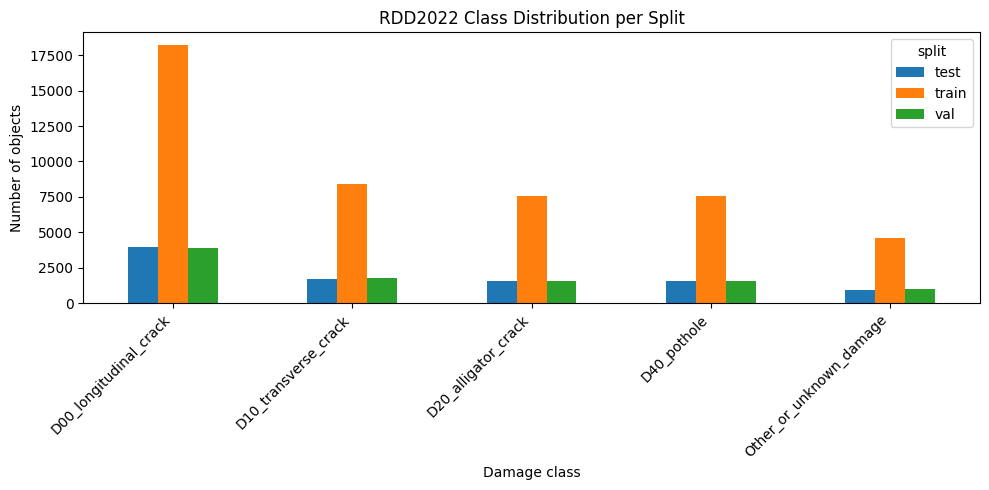

In [40]:
pivot_dist = class_distribution.pivot(
    index="class_name",
    columns="split",
    values="count"
).fillna(0)

pivot_dist.plot(kind="bar", figsize=(10, 5))

plt.title("RDD2022 Class Distribution per Split")
plt.xlabel("Damage class")
plt.ylabel("Number of objects")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

##### 7. Check raw class IDs in the dataset

In [41]:
raw_class_counts = (
    labels_df[labels_df["is_empty"] == False]["class_id"]
    .value_counts()
    .sort_index()
)

raw_class_counts

class_id
0.0    26016
1.0    11830
2.0    10617
3.0    10705
4.0     6544
Name: count, dtype: int64

In [42]:
print("Unique class IDs found:")
print(sorted(labels_df[labels_df["is_empty"] == False]["class_id"].dropna().unique()))

print("\nNumber of objects with unmapped class name:")
print(labels_df[
    (labels_df["is_empty"] == False) &
    (labels_df["class_name"].isna())
].shape[0])

Unique class IDs found:
[np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]

Number of objects with unmapped class name:
0


###### Example of labels that are not mapped

In [44]:
unmapped_examples = labels_df[
    (labels_df["is_empty"] == False) &
    (labels_df["class_name"].isna())
]

unmapped_examples.head()

,split,image_id,class_id,x_center,y_center,bbox_width,bbox_height,is_empty,class_name
